# Exercise 1 — Stellar metallicities with the Bench

*Covers notebooks 01–04. Difficulty: ★☆☆☆☆*

How faint and how fast can LFAST deliver LAMOST-quality metallicities, one star at a time?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

At R ~ 1800 the Bench sample configuration is LAMOST-like, so LAMOST tells us what to expect:
[Fe/H] to about 0.1 dex for FGK stars once the SNR per pixel exceeds 20 to 30 (Wu et al. 2014;
Luo et al. 2015), and about 0.05 dex only with data-driven methods trained on high-resolution
labels, which need SNR > 50 (Ho et al. 2017; Xiang et al. 2019). The ETC works per resel
(2.2 pixels), so SNR 20 per pixel is about 30 per resel. The metallicity information sits in the
Mg b region, 500 to 560 nm.

LFAST is not a multiplexed survey instrument: all telescopes point at one star. Its niche is
depth on individually selected targets (Gaia XP metal-poor candidates, stream members, faint halo
giants). The questions are *how faint* and *how fast*.

In [2]:
bench = LFASTETC("bench_r1800", n_telescopes=20)
stars = {"G dwarf 5800 K": 5800, "K dwarf 4500 K": 4500, "M dwarf 3500 K": 3500}
mags = np.linspace(9, 20, 45)
WINDOW = (500, 560)          # the Mg b region
OVERHEAD = 600.0             # s per target: slew, acquisition, read-out

### 1.1 — Exposure time to reach the SNR thresholds

Plot the exposure time versus V for the three stars, in two panels: SNR 30 (about 0.1 dex) and
SNR 75 (what the 0.05 dex methods need), with the 15 minute and one hour lines marked. Why do the
three curves lie almost on top of each other?

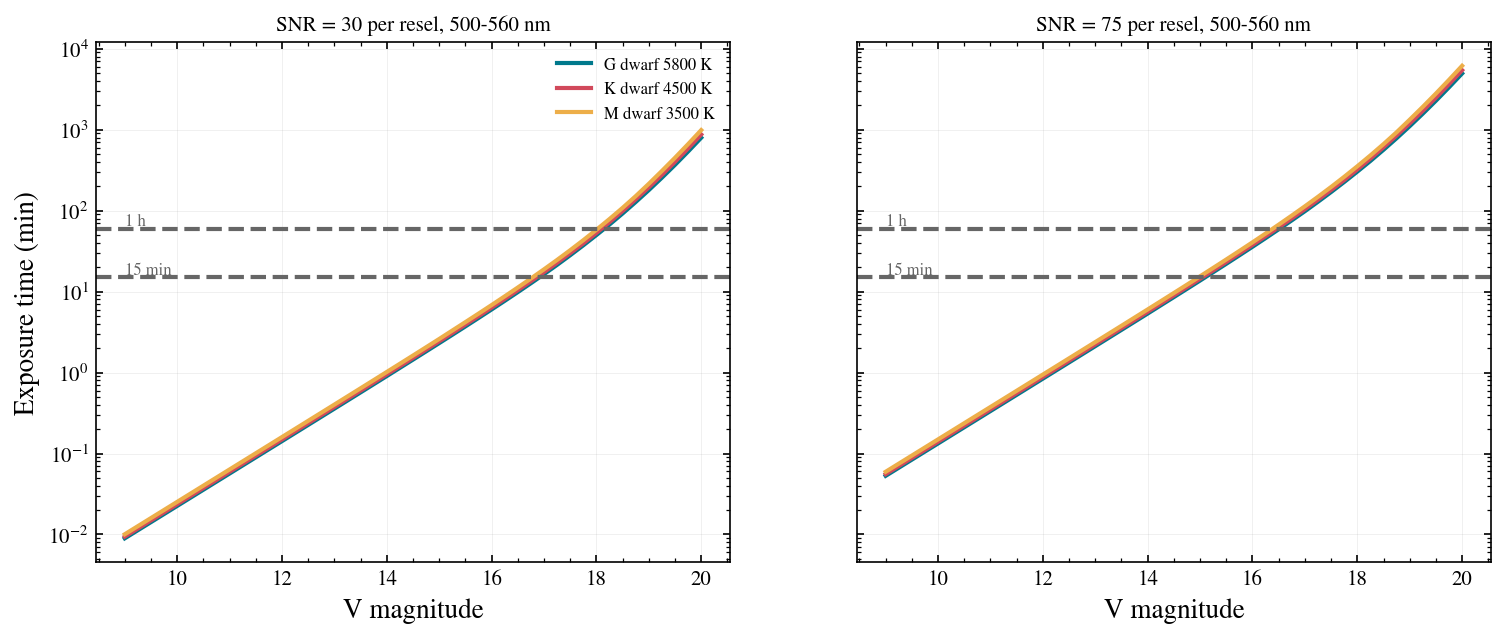

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, snr_t in zip(axes, (30, 75)):
    for label, teff in stars.items():
        t = bench.exptime_vs_mag(Source.blackbody(teff, 0, "V"), mags, snr=snr_t, wavelength=WINDOW)
        ax.plot(mags, t / 60, label=label)
    ax.set_yscale("log"); ax.set_xlabel("V magnitude"); ax.set_title(f"SNR = {snr_t} per resel, 500-560 nm")
    for h, txt in ((15, "15 min"), (60, "1 h")):
        ax.axhline(h, color="0.4", ls="--"); ax.text(mags[0], h * 1.1, txt, fontsize=8, color="0.4")
axes[0].set_ylabel("Exposure time (min)"); axes[0].legend()
# The window sits inside the V band, where the magnitude pins the flux, so spectral type only enters
# through the slope of the SED across 60 nm. Normalise in I instead and the curves separate.

### 1.2 — Survey depth

Make a table of the limiting V (median SNR over 500 to 560 nm) for both SNR targets and all three
stars, in 5, 15 and 60 minutes. Read it as: *with this exposure, every star brighter than this V
gets a metallicity at this precision.* How does the depth grow with time, and what does that say
about which noise term dominates?

> ✏️ **Before you run the next cell:** with 20 telescopes, how faint a G dwarf reaches SNR 30 per resel in 15 minutes? V = 15, 17 or 19? Write your guess down (or put it in the room poll), then run.

In [4]:
exps = (300, 900, 3600)
depth = pd.DataFrame({(label.split()[0], f"SNR {snr_t}"): [bench.limiting_magnitude(Source.blackbody(teff, 0, "V"), t, snr_t, wavelength=WINDOW) for t in exps]
                      for label, teff in stars.items() for snr_t in (30, 75)},
                     index=pd.Index([t // 60 for t in exps], name="exposure (min)"))
depth.round(1)
# 5 -> 15 min (x3) gains ~1.1 mag, 15 -> 60 min (x4) ~1.25 mag: between the source-limited
# 2.5 log10(t) (1.2, 1.5 mag) and the sky-limited 1.25 log10(t) (0.6, 0.75), closer to the former.

G             K             M       
               SNR 30 SNR 75 SNR 30 SNR 75 SNR 30 SNR 75
exposure (min)                                          
5                15.8   13.9   15.8   13.9   15.7   13.8
15               16.9   15.1   16.9   15.0   16.8   15.0
60               18.2   16.5   18.1   16.5   18.0   16.4

### 1.3 — Distance reach by tracer

Turn the one-hour SNR 30 limit into a distance (ignoring extinction) for a G dwarf ($M_V$ = +4.8),
a K giant ($M_V$ = +0.5) and a star at the tip of the red giant branch ($M_V$ = -2.5). Use the
5800 K blackbody for the dwarf and 4500 K for the giants.

In [5]:
tracers = {"G dwarf (M_V=+4.8)": (5800, 4.8), "K giant (M_V=+0.5)": (4500, 0.5), "RGB tip (M_V=-2.5)": (4500, -2.5)}
for label, (teff, MV) in tracers.items():
    vlim = bench.limiting_magnitude(Source.blackbody(teff, 0, "V"), 3600, 30, wavelength=WINDOW)
    print(f"{label:22s}: V < {vlim:.1f}  ->  {10**((vlim - MV + 5) / 5) / 1000:6.1f} kpc")
# Dwarfs probe the thick disc; giants reach into the halo.

G dwarf (M_V=+4.8)    : V < 18.2  ->     4.7 kpc
K giant (M_V=+0.5)    : V < 18.1  ->    33.1 kpc
RGB tip (M_V=-2.5)    : V < 18.1  ->   131.9 kpc


### 1.4 — Survey throughput

One star at a time, so the number of stars per 8 hour night is
$N = 8\,\mathrm{h} / (t_{exp}(V) + t_{overhead})$. Plot it for G dwarfs at SNR 30 with the 10 minute
overhead. Where does the overhead stop mattering, and what does that mean for a bigger array?

Text(0.5, 1.0, 'G dwarfs, Bench R~1800, 20 telescopes, 10 min overhead')

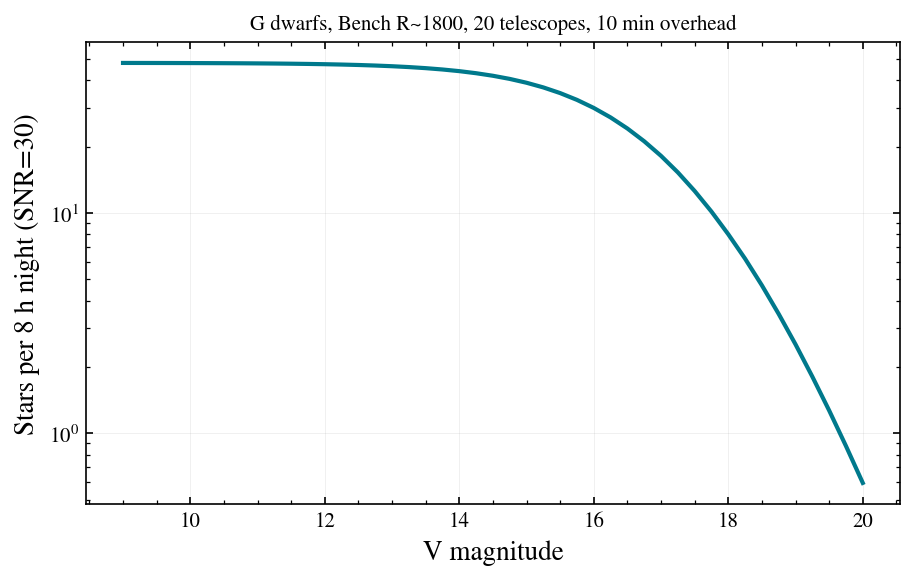

In [6]:
t = bench.exptime_vs_mag(Source.blackbody(5800, 0, "V"), mags, snr=30, wavelength=WINDOW)
n_per_night = 8 * 3600 / (t + OVERHEAD)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mags, n_per_night)
ax.set_yscale("log"); ax.set_xlabel("V magnitude"); ax.set_ylabel("Stars per 8 h night (SNR=30)")
ax.set_title(f"G dwarfs, Bench R~1800, 20 telescopes, {OVERHEAD / 60:.0f} min overhead")
# Bright stars are overhead-limited: at most 48 per night whatever the array size. The exposure
# equals the overhead at V ~ 16.5; only fainter than that does a larger array help.

### 1.5 — Gaia XP candidates

Gaia XP photometric metallicities (to G < 17.65) contain about 2 x 10$^5$ candidates with
[Fe/H] < -2 (Xylakis-Dornbusch et al. 2024). How long does the nominal array take to confirm a
K giant candidate at V = 16, 17.5, 19 and 20 at SNR 30? Which of those could a season of nights
get through?

In [7]:
giant = Source.blackbody(4500, 0, "V")
for m, ti in zip((16, 17.5, 19, 20), bench.exptime_vs_mag(giant, [16, 17.5, 19, 20], snr=30, wavelength=WINDOW)):
    print(f"V = {m:4.1f}: {ti / 60:6.1f} min  ({8 * 3600 / (ti + OVERHEAD):5.1f} per night)")

V = 16.0:    6.3 min  ( 29.4 per night)
V = 17.5:   29.8 min  ( 12.1 per night)
V = 19.0:  194.3 min  (  2.4 per night)
V = 20.0:  873.1 min  (  0.5 per night)


> 🤖 **Ask Jupyter AI:** *Move the metric window to the G band (425 to 435 nm), the window that matters for carbon-enhanced metal-poor stars, and redo the depth table. Then switch to the bench_1200_28p7_o2 preset (R ~ 7600 around 400 nm): does the higher resolution pay for itself in exposure time at fixed SNR per resel?*

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/lfast-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*